# 04 · Final evaluation on the unseen test split
The test split is used once. This notebook **recomputes** the headline metrics from the saved model to show they are not hand-entered.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
from ml import config
report = lambda name: json.loads((config.REPORTS_DIR / name).read_text())

In [2]:
from ml.inference import Predictor
from ml.preprocessing.data import load_split, feature_target
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix
pred = Predictor.load()
X, y = feature_target(load_split('test'))
p = pred.bundle['model'].predict_proba(pred.bundle['feature_builder'].transform(X))[:, 1]
thr = pred.policy.high_threshold
print('PR-AUC ', round(average_precision_score(y, p), 4))
print('ROC-AUC', round(roc_auc_score(y, p), 4))
print('threshold', thr)
confusion_matrix(y, p >= thr)

PR-AUC  0.893
ROC-AUC 0.966
threshold 0.3931


array([[1922,   10],
       [  11,   57]])

In [3]:
t = report('metrics.json')['test']
{k: t[k] for k in ['pr_auc','roc_auc','precision','recall','f1','brier']} | {'bootstrap_95ci': t['bootstrap_95ci']}

{'pr_auc': 0.893, 'roc_auc': 0.966, 'precision': 0.8507, 'recall': 0.8382, 'f1': 0.8444, 'brier': 0.0076, 'bootstrap_95ci': {'pr_auc': [0.8234, 0.9547], 'roc_auc': [0.9321, 0.9925], 'precision': [0.76, 0.9306], 'recall': [0.75, 0.9259], 'f1': [0.7736, 0.9104]}}

In [4]:
pd.DataFrame(t['risk_bands']).T

,records,actual_failures,observed_failure_rate,wilson_95ci,share_of_all_failures
LOW,1831,6,0.0033,"[0.0015, 0.0071]",0.0882
MEDIUM,102,5,0.049,"[0.0211, 0.1097]",0.0735
HIGH,67,57,0.8507,"[0.7466, 0.9169]",0.8382


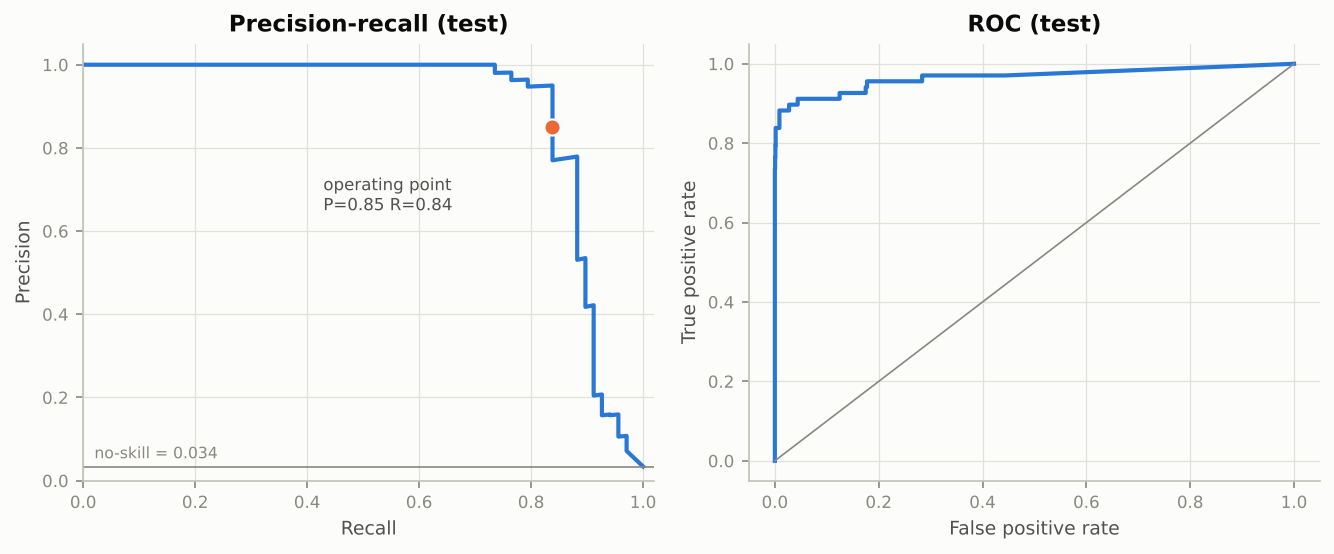

In [5]:
from IPython.display import Image
Image(str(config.FIGURES_DIR / '08_test_pr_roc.png'))

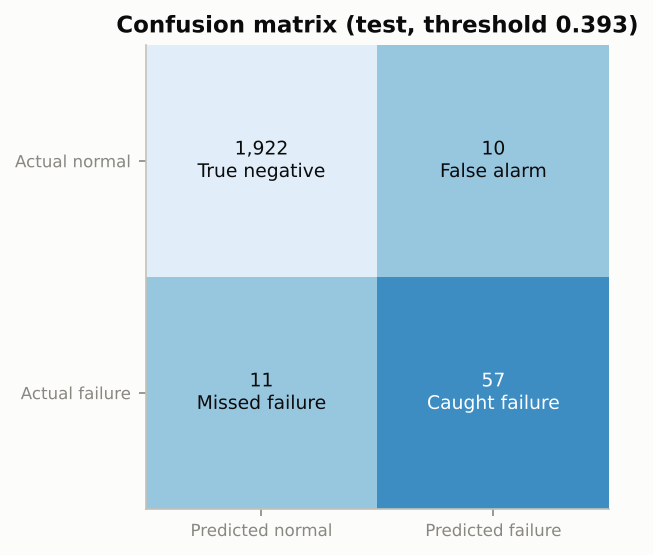

In [6]:
Image(str(config.FIGURES_DIR / '09_test_confusion_matrix.png'))

## Robustness across five random splits

In [7]:
r = report('metrics.json')['robustness']
pd.DataFrame(r['per_seed']).set_index('seed')

,pr_auc,roc_auc,precision,recall,f1,threshold
seed,,,,,,
7,0.9095,0.9814,0.8406,0.8529,0.8467,0.2765
21,0.9081,0.9746,0.9828,0.8382,0.9048,0.3835
42,0.8930,0.9660,0.8507,0.8382,0.8444,0.3931
99,0.8983,0.9737,0.8406,0.8529,0.8467,0.2545
2026,0.9009,0.9728,0.8769,0.8382,0.8571,0.3629


## Explainability

In [8]:
e = report('explainability.json')
print(e['method'], '|', e['global_sample'])
pd.DataFrame(e['shap_global_importance_test']).set_index('feature')

Exact path-dependent TreeSHAP (Python implementation), probability space | 600 randomly sampled test rows (seed 42)


,label,mean_abs_shap
feature,,
strain_nm_min,Tool strain (wear x torque),0.0163
rotational_speed_rpm,Rotational speed,0.0144
temp_diff_k,Process-air temperature gap,0.0143
power_w,Mechanical power,0.0140
tool_wear_min,Tool wear,0.0092
torque_nm,Torque,0.0072
air_temp_k,Air temperature,0.0025
type_ordinal,Product quality type,0.0023
process_temp_k,Process temperature,0.0009


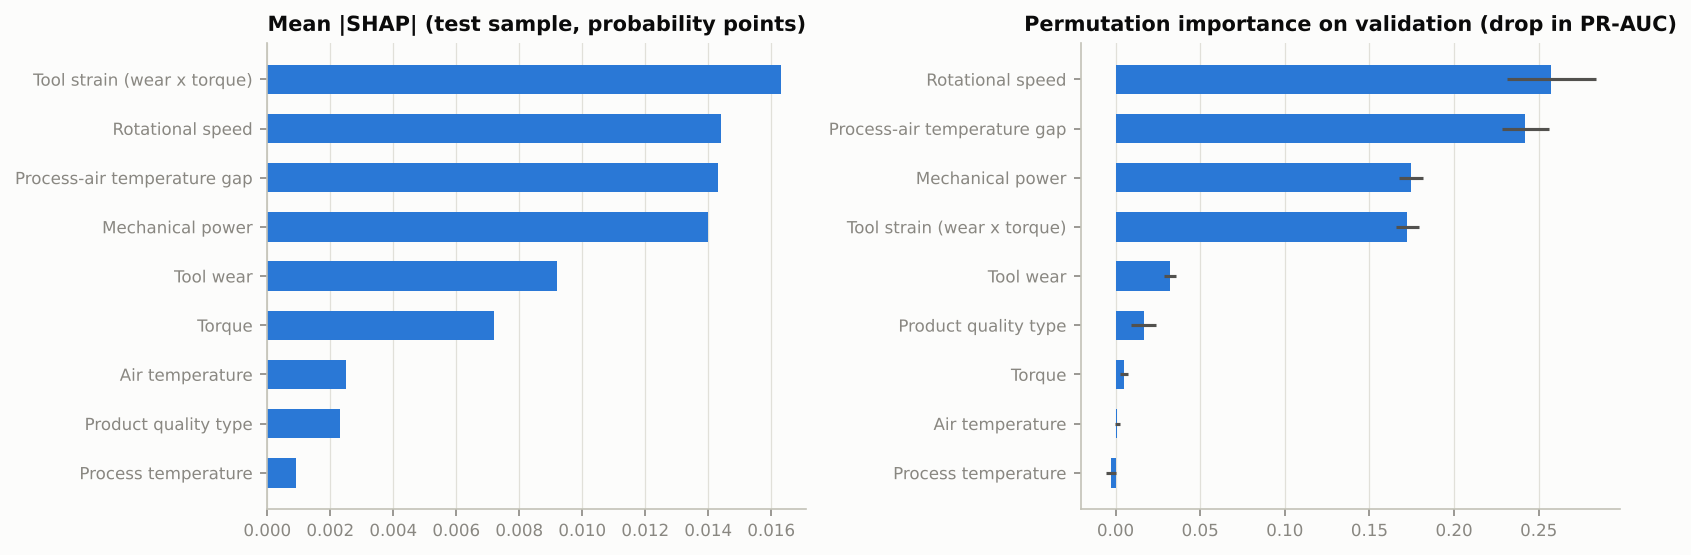

In [9]:
Image(str(config.FIGURES_DIR / '10_feature_importance.png'))

## Prediction on a new, unseen record

In [10]:
new = {'type': 'L', 'air_temp_k': 301.2, 'process_temp_k': 310.4, 'rotational_speed_rpm': 1325, 'torque_nm': 61.0, 'tool_wear_min': 212}
res = pred.predict([new])[0]
print(res['failure_probability'], res['risk_level'])
print(res['explanation'])

0.9827 HIGH
The model estimates a high failure probability of 98.3% (HIGH risk). The factors contributing most toward a higher prediction are tool strain (wear x torque) (12,932 Nm·min) and tool wear (212 min). These are associations the model has learned from historical (synthetic) data, not proof of cause.


## Failure-mode model (conditional on failure)

In [11]:
fm = report('failure_mode.json')
print(fm['scope'])
pd.DataFrame(fm['test']['per_class']).T

Conditional on failure. Classes TWF/HDF/PWF/OSF; RNF excluded (random by construction).


,precision,recall,f1,support
twf,0.8,1.0000,0.8889,8.0
hdf,1.0,1.0000,1.0000,21.0
pwf,1.0,0.9375,0.9677,16.0
osf,1.0,0.9375,0.9677,16.0
